# Training Model — Prediksi Popularitas Buku (CRISP-DM)

Notebook ini berisi alur yang sama dengan `train_model.py`:
load data → pembersihan → labeling (Q75) → encoding → feature engineering →
5-fold cross validation (SMOTE di dalam fold) → training final → threshold tuning →
evaluasi test set → simpan `model.pkl` untuk dashboard.

> Bisa dibuka dari folder `notebooks/` atau dari root proyek; sel pertama otomatis pindah ke root.
> Menjalankan semua sel akan **menimpa `models/model.pkl`**.

In [1]:
import os
import tempfile

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score
)
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

%matplotlib inline

# Semua path relatif terhadap root proyek, baik notebook dibuka dari notebooks/ maupun dari root
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
print("Root proyek:", ROOT)
sns.set_theme(style="whitegrid")

## 1. Load Data

In [2]:
df = pd.read_csv("data/dataset.csv")
df = df.fillna("unknown")

print(f"Total Data  : {len(df):,} baris")
print(f"Total Kolom : {df.shape[1]} kolom")
df.head()

Total Data  : 270,170 baris
Total Kolom : 12 kolom


,ISBN,Book_Title,Book_Author,Publisher,Year,jumlah_pinjam,book_age,title_length,author_freq,publisher_freq,log_pinjam,kategori
0,0330364251,Zombie Bums From Uranus,andy griffiths,pan macmillan,2003,4,22,23,8,545,1.609438,1
1,3257062303,Liebesfluchten: Geschichten,bernhard schlink,diogenes,2000,1,25,27,18,114,0.693147,0
2,0679024913,Fodor's Affordable Europe (Fodor's Afforable),christopher billy,fodor's travel publications,1993,1,32,45,1,127,0.693147,0
3,0449200906,Way of the Bull,leo buscaglia,ballantine books,1983,7,42,15,14,3775,2.079442,1
4,0818404213,Make 'Em Pay: Ultimate Revenge Techniques for ...,george hayduke,carol publishing corporation,1986,1,39,66,5,194,0.693147,0


## 2. Clean Text

In [3]:
df['Book_Author'] = df['Book_Author'].astype(str).str.lower().str.strip()
df['Publisher']   = df['Publisher'].astype(str).str.lower().str.strip()
df['Book_Title']  = df['Book_Title'].astype(str).str.lower().str.strip()
df['ISBN']        = df['ISBN'].astype(str).str.strip()

## 3. Label — Distribusi Natural (Q75)
Buku dianggap **populer** jika `jumlah_pinjam` di atas kuartil ke-3.

In [4]:
threshold = df['jumlah_pinjam'].quantile(0.75)
df['kategori'] = (df['jumlah_pinjam'] > threshold).astype(int)

total     = len(df)
n_populer = df['kategori'].sum()
n_tidak   = total - n_populer

print(f"Threshold Label (Q75) : {threshold}")
print(f"Tidak Populer (0)     : {n_tidak:,} ({n_tidak/total*100:.1f}%)")
print(f"Populer (1)           : {n_populer:,} ({n_populer/total*100:.1f}%)")

Threshold Label (Q75) : 3.0
Tidak Populer (0)     : 216,571 (80.2%)
Populer (1)           : 53,599 (19.8%)


## 4. Encoding

In [5]:
le_author    = LabelEncoder()
le_publisher = LabelEncoder()

df['Book_Author'] = le_author.fit_transform(df['Book_Author'])
df['Publisher']   = le_publisher.fit_transform(df['Publisher'])

## 5. Feature Engineering

In [6]:
# Fitur dasar
df['book_age']         = 2025 - pd.to_numeric(df['Year'], errors='coerce').fillna(2025)
df['title_length']     = df['Book_Title'].str.len()
df['title_word_count'] = df['Book_Title'].str.split().str.len()

# Dari ISBN: panjang (10 vs 13) dan digit pertama (kode bahasa/negara)
df['isbn_length'] = df['ISBN'].str.replace('-', '').str.len()
df['isbn_prefix'] = df['ISBN'].str[:1].apply(lambda x: int(x) if x.isdigit() else -1)

# Kompleksitas judul
df['avg_word_length'] = df['Book_Title'].apply(
    lambda x: np.mean([len(w) for w in str(x).split()]) if str(x).split() else 0
)

# Era buku (dekade)
df['decade'] = (df['book_age'] // 10) * 10

## 6. Split Data, lalu Frequency Features (anti-leakage)
Frekuensi author/publisher dihitung **hanya dari data train** supaya test set tidak bocor.

In [7]:
y = df['kategori']

X_train_temp, X_test_temp, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=42
)

author_freq_map    = X_train_temp['Book_Author'].value_counts().to_dict()
publisher_freq_map = X_train_temp['Publisher'].value_counts().to_dict()

X_train_temp = X_train_temp.copy()
X_test_temp  = X_test_temp.copy()

for part in (X_train_temp, X_test_temp):
    part['author_freq']        = part['Book_Author'].map(author_freq_map).fillna(1)
    part['publisher_freq']     = part['Publisher'].map(publisher_freq_map).fillna(1)
    part['author_freq_log']    = np.log1p(part['author_freq'])
    part['publisher_freq_log'] = np.log1p(part['publisher_freq'])
    part['author_x_pub']       = part['Book_Author'] * part['Publisher']
    part['age_x_author']       = part['book_age'] * part['author_freq_log']

## 7. Final Features

In [8]:
features = [
    'Book_Author', 'Publisher', 'book_age', 'decade',
    'title_length', 'title_word_count', 'avg_word_length',
    'isbn_length', 'isbn_prefix',
    'author_freq', 'publisher_freq', 'author_freq_log', 'publisher_freq_log',
    'author_x_pub', 'age_x_author',
]

X_train = X_train_temp[features]
X_test  = X_test_temp[features]

print(f"Total Fitur : {len(features)}")
X_train.head()

Total Fitur : 15


,Book_Author,Publisher,book_age,decade,title_length,title_word_count,avg_word_length,isbn_length,isbn_prefix,author_freq,publisher_freq,author_freq_log,publisher_freq_log,author_x_pub,age_x_author
168353,68395,15788,24,20,30,4,6.750000,10,0,1,185,0.693147,5.225747,1079820260,16.635532
238770,52496,6626,31,30,28,6,3.833333,10,0,42,506,3.761200,6.228511,347838496,116.597204
130706,10591,11344,43,40,62,8,6.875000,10,0,6,10,1.945910,2.397895,120144304,83.674136
245975,5157,13551,22,20,69,10,5.800000,10,0,38,3360,3.663562,8.119994,69882507,80.598356
183642,39242,10038,33,30,85,16,4.375000,10,0,1,19,0.693147,2.995732,393911196,22.873857


## 8. Stratified 5-Fold Cross Validation
SMOTE dijalankan **di dalam** setiap training fold (lewat `imblearn.Pipeline`),
bukan sebelum CV. Probabilitas out-of-fold (OOF) disimpan untuk threshold tuning.

In [9]:
def make_rf():
    return RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features='sqrt',
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42,
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []
oof_proba = np.zeros(len(X_train))

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    fold_pipeline = Pipeline([('smote', SMOTE(random_state=42)), ('model', make_rf())])
    fold_pipeline.fit(X_fold_train, y_fold_train)

    y_proba_fold = fold_pipeline.predict_proba(X_fold_val)[:, 1]
    y_pred_fold  = (y_proba_fold >= 0.50).astype(int)
    oof_proba[val_idx] = y_proba_fold

    fold_results.append({
        'Fold': fold,
        'Accuracy':  accuracy_score(y_fold_val, y_pred_fold),
        'Precision': precision_score(y_fold_val, y_pred_fold, average='weighted', zero_division=0),
        'Recall':    recall_score(y_fold_val, y_pred_fold, average='weighted', zero_division=0),
        'F1-Score':  f1_score(y_fold_val, y_pred_fold, average='weighted', zero_division=0),
    })
    print(f"Fold {fold} selesai — F1 {fold_results[-1]['F1-Score']:.4f}")

cv_results = pd.DataFrame(fold_results)
cv_mean = {'Fold': 'Rata-rata', **cv_results.drop(columns='Fold').mean().to_dict()}
cv_results = pd.concat([cv_results, pd.DataFrame([cv_mean])], ignore_index=True)

print(f"\nMean CV F1 : {cv_mean['F1-Score'] * 100:.2f}%")
print(f"Std CV F1  : {cv_results.iloc[:5]['F1-Score'].std() * 100:.2f}%")
cv_results.round(4)

Fold 1 selesai — F1 0.7809


Fold 2 selesai — F1 0.7832


Fold 3 selesai — F1 0.7833


Fold 4 selesai — F1 0.7840


Fold 5 selesai — F1 0.7827

Mean CV F1 : 78.28%
Std CV F1  : 0.12%


,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.7738,0.7904,0.7738,0.7809
1,2,0.7766,0.7918,0.7766,0.7832
2,3,0.7761,0.7929,0.7761,0.7833
3,4,0.7775,0.7924,0.7775,0.7840
4,5,0.7757,0.7919,0.7757,0.7827
5,Rata-rata,0.7759,0.7919,0.7759,0.7828


## 9. SMOTE pada Seluruh Data Training

In [10]:
print(f"Sebelum -> 0: {y_train.value_counts()[0]:,} | 1: {y_train.value_counts()[1]:,}")

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

counts = pd.Series(y_train_sm).value_counts()
print(f"Sesudah -> 0: {counts[0]:,} | 1: {counts[1]:,}")

Sebelum -> 0: 173,257 | 1: 42,879


Sesudah -> 0: 173,257 | 1: 173,257


## 10–11. Training Model Final

In [11]:
model = make_rf()
model.fit(X_train_sm, y_train_sm)
print("Training selesai.")

Training selesai.


## 12. Threshold Tuning (berdasarkan OOF, bukan test set)
Test set tetap belum tersentuh sampai evaluasi akhir.

In [12]:
best_threshold = 0.50
best_f1_macro = -1

for thresh in np.arange(0.25, 0.70, 0.05):
    f1_macro_t = f1_score(y_train, (oof_proba >= thresh).astype(int), average='macro', zero_division=0)
    if f1_macro_t > best_f1_macro:
        best_f1_macro, best_threshold = f1_macro_t, thresh

print(f"Threshold terbaik : {best_threshold:.2f}")
print(f"OOF F1 Macro      : {best_f1_macro * 100:.2f}%")

Threshold terbaik : 0.55
OOF F1 Macro      : 67.05%


## 13. Evaluasi Akhir — Test Set

In [13]:
y_proba = model.predict_proba(X_test)[:, 1]
y_pred  = (y_proba >= best_threshold).astype(int)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1_w = f1_score(y_test, y_pred, average='weighted', zero_division=0)
f1_m = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_0 = f1_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
auc  = roc_auc_score(y_test, y_proba)
cm   = confusion_matrix(y_test, y_pred)

print(f"Threshold Terbaik   : {best_threshold:.2f}")
print(f"Accuracy            : {acc*100:.2f}%")
print(f"Precision (w)       : {prec*100:.2f}%")
print(f"Recall (w)          : {rec*100:.2f}%")
print(f"F1 Score (weighted) : {f1_w*100:.2f}%")
print(f"F1 Score (macro)    : {f1_m*100:.2f}%")
print(f"F1 Kelas 0          : {f1_0*100:.2f}%")
print(f"F1 Kelas 1 (populer): {f1_1*100:.2f}%")
print(f"AUC-ROC             : {auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Tidak Populer', 'Populer']))

Threshold Terbaik   : 0.55
Accuracy            : 79.35%
Precision (w)       : 79.02%
Recall (w)          : 79.35%
F1 Score (weighted) : 79.18%
F1 Score (macro)    : 67.01%
F1 Kelas 0          : 87.19%
F1 Kelas 1 (populer): 46.83%
AUC-ROC             : 0.7757

               precision    recall  f1-score   support

Tidak Populer       0.87      0.88      0.87     43314
      Populer       0.48      0.46      0.47     10720

     accuracy                           0.79     54034
    macro avg       0.67      0.67      0.67     54034
 weighted avg       0.79      0.79      0.79     54034



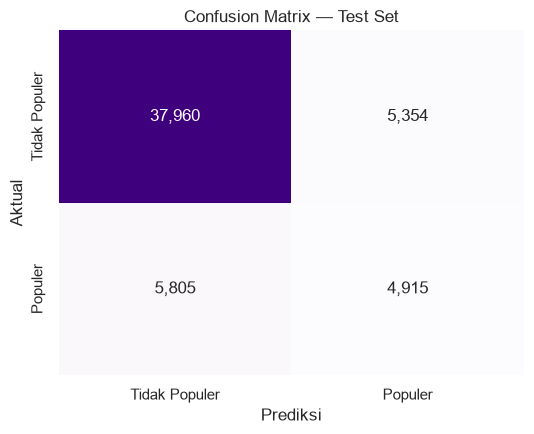

In [14]:
labels = ['Tidak Populer', 'Populer']
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Purples', cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.show()

## 13B. Simpan Hasil Cross Validation

In [15]:
cv_results.to_csv("output/hasil_5_fold_cross_validation.csv", index=False)
print("Tabel 5-Fold tersimpan -> output/hasil_5_fold_cross_validation.csv")

Tabel 5-Fold tersimpan -> hasil_5_fold_cross_validation.csv


## 14. Feature Importance

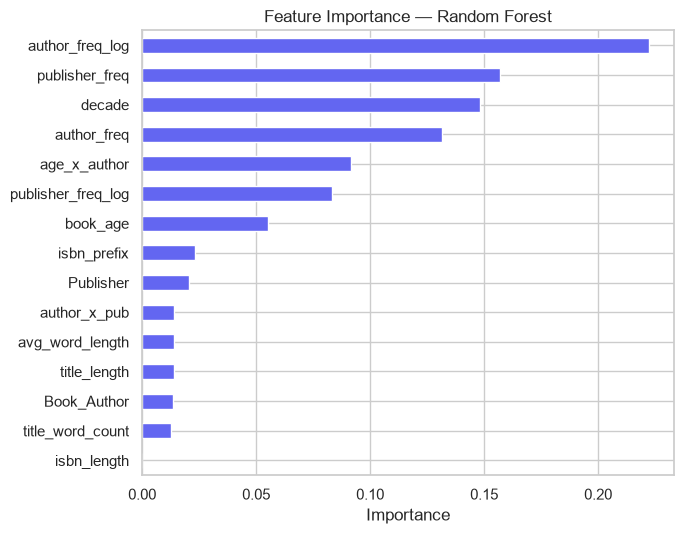

,importance
author_freq_log,0.2222
publisher_freq,0.1570
decade,0.1481
author_freq,0.1315
age_x_author,0.0914
publisher_freq_log,0.0831
book_age,0.0550
isbn_prefix,0.0233
Publisher,0.0205
author_x_pub,0.0141


In [16]:
importance = (pd.Series(model.feature_importances_, index=features)
                .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
importance.plot.barh(ax=ax, color='#6366f1')
ax.set_title('Feature Importance — Random Forest')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4).to_frame('importance')

## 15. Ringkasan untuk Penulisan Ilmiah

In [17]:
ringkasan = {
    'Dataset':            f"{len(df):,} data buku",
    'Threshold Populer':  f"jumlah_pinjam > {threshold:.0f} (Q75)",
    'Rasio Kelas':        f"{n_tidak/total*100:.0f}% tidak populer, {n_populer/total*100:.0f}% populer",
    'Metode Balancing':   "SMOTE (Synthetic Minority Oversampling)",
    'Algoritma':          f"Random Forest ({model.n_estimators} trees, depth {model.max_depth})",
    'Split Data':         "80% train, 20% test (stratified)",
    'Cross Validation':   "5-fold Stratified CV",
    'Mean CV Accuracy':   f"{cv_mean['Accuracy']*100:.2f}%",
    'Mean CV Precision':  f"{cv_mean['Precision']*100:.2f}%",
    'Mean CV Recall':     f"{cv_mean['Recall']*100:.2f}%",
    'Mean CV F1-Score':   f"{cv_mean['F1-Score']*100:.2f}%",
    'Threshold Optimal':  f"{best_threshold:.2f}",
    'Akurasi':            f"{acc*100:.2f}%",
    'F1 Macro':           f"{f1_m*100:.2f}%",
    'AUC-ROC':            f"{auc:.4f}",
}
pd.Series(ringkasan).to_frame('Nilai')

,Nilai
Dataset,"270,170 data buku"
Threshold Populer,jumlah_pinjam > 3 (Q75)
Rasio Kelas,"80% tidak populer, 20% populer"
Metode Balancing,SMOTE (Synthetic Minority Oversampling)
Algoritma,"Random Forest (200 trees, depth 15)"
Split Data,"80% train, 20% test (stratified)"
Cross Validation,5-fold Stratified CV
Mean CV Accuracy,77.59%
Mean CV Precision,79.19%
Mean CV Recall,77.59%


## 16. Simpan Model
Bundle ini disimpan ke `models/model.pkl` dan dibaca oleh `app.py`. `eval_metrics` yang membuat akurasi &
confusion matrix muncul di halaman Dashboard.

In [18]:
model_bundle = {
    'model': model,
    'features': features,
    'feature_names': features,
    'le_author': le_author,
    'le_publisher': le_publisher,
    'author_freq_map': author_freq_map,
    'publisher_freq_map': publisher_freq_map,
    'best_threshold': best_threshold,
    'cv_results': cv_results.to_dict(orient='records'),
    'eval_metrics': {
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1': round(f1_w, 4),
        'f1_macro': round(f1_m, 4),
        'auc_roc': round(auc, 4),
        'confusion_matrix': cm.tolist(),
    },
}

save_path = 'models/model.pkl'
try:
    joblib.dump(model_bundle, save_path)
except OSError:
    save_path = os.path.join(tempfile.gettempdir(), 'library_ml_model.pkl')
    joblib.dump(model_bundle, save_path)

print(f"MODEL TERSIMPAN -> {save_path}")
print(f"best_threshold  : {best_threshold:.2f}")
print(f"features        : {len(features)}")

MODEL TERSIMPAN -> model.pkl
best_threshold  : 0.55
features        : 15
